# SEGWO Response Analysis — Publication-Ready Figures

This notebook generates all figures for the paper from pre-computed results stored in `./data`.
No heavy computation is performed here; every cell only loads arrays and produces plots.

In [1]:
import os
os.environ["PATH"] = '/Users/lorenzo.speri/Library/Application Support/Code/User/globalStorage/github.copilot-chat/debugCommand:/Users/lorenzo.speri/Library/Application Support/Code/User/globalStorage/github.copilot-chat/copilotCli:/opt/miniconda3/envs/lisa_resp/bin:/opt/miniconda3/condabin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/appleinternal/bin:/opt/pmk/env/global/bin:/Library/Apple/usr/bin:/Library/TeX/texbin:/Users/lorenzo.speri/Library/Application Support/Code/User/globalStorage/github.copilot-chat/debugCommand:/Users/lorenzo.speri/Library/Application Support/Code/User/globalStorage/github.copilot-chat/copilotCli:/Users/lorenzo.speri/.vscode/extensions/ms-python.debugpy-2026.6.0-darwin-arm64/bundled/scripts/noConfigScripts'

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py
import healpy as hp
from matplotlib.colors import LogNorm
from lisaconstants.indexing import LINKS
from lisaconstants import C
from plot_utils import plot_orbit_3d
from lisaorbits import StaticConstellation
import corner
from eryn.backends import HDFBackend


plt.rcParams.update()
# ── Publication-quality matplotlib settings ─────────────────────────────────
plt.rcParams.update({
    'text.usetex':       True,        # set True if a LaTeX install is available
    'font.family':       'times',
    'font.size':         9,
    'axes.labelsize':    9,
    'axes.titlesize':    9,
    'xtick.labelsize':   8,
    'ytick.labelsize':   8,
    'legend.fontsize':   8,
    'legend.frameon':    True,
    'legend.framealpha': 0.8,
    'figure.dpi':        150,
    'savefig.dpi':       300,
    'savefig.bbox':      'tight',
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'grid.linestyle':    ':',
    'lines.linewidth':   1.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

# ── Figure width constants (inches) ─────────────────────────────────────────
COL1 = 3.5   # single-column
COL2 = 7.2   # double-column

# ── Polarisation labels ──────────────────────────────────────────────────────
POLS = (r'$h_+$', r'$h_\times$')

# ── Output directory for paper-quality PDFs ──────────────────────────────────
PAPER_DIR = "paper_plots"
os.makedirs(PAPER_DIR, exist_ok=True)


/opt/miniconda3/envs/resp/lib/python3.12/site-packages/lisaconstants/compat/astropy.py:252: UserWarning: The following constants differ between lisaconstants and the version of astropy you have installed: VACUUM_PERMEABILITY. The recommended version of astropy is 7.2.0. Use a different one at your own risks. 
You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.2
  warnings.warn(


3D orbit plot saved to paper_plots/lisa_orbit_.png
3D orbit plot saved to paper_plots/toy_orbit_.png


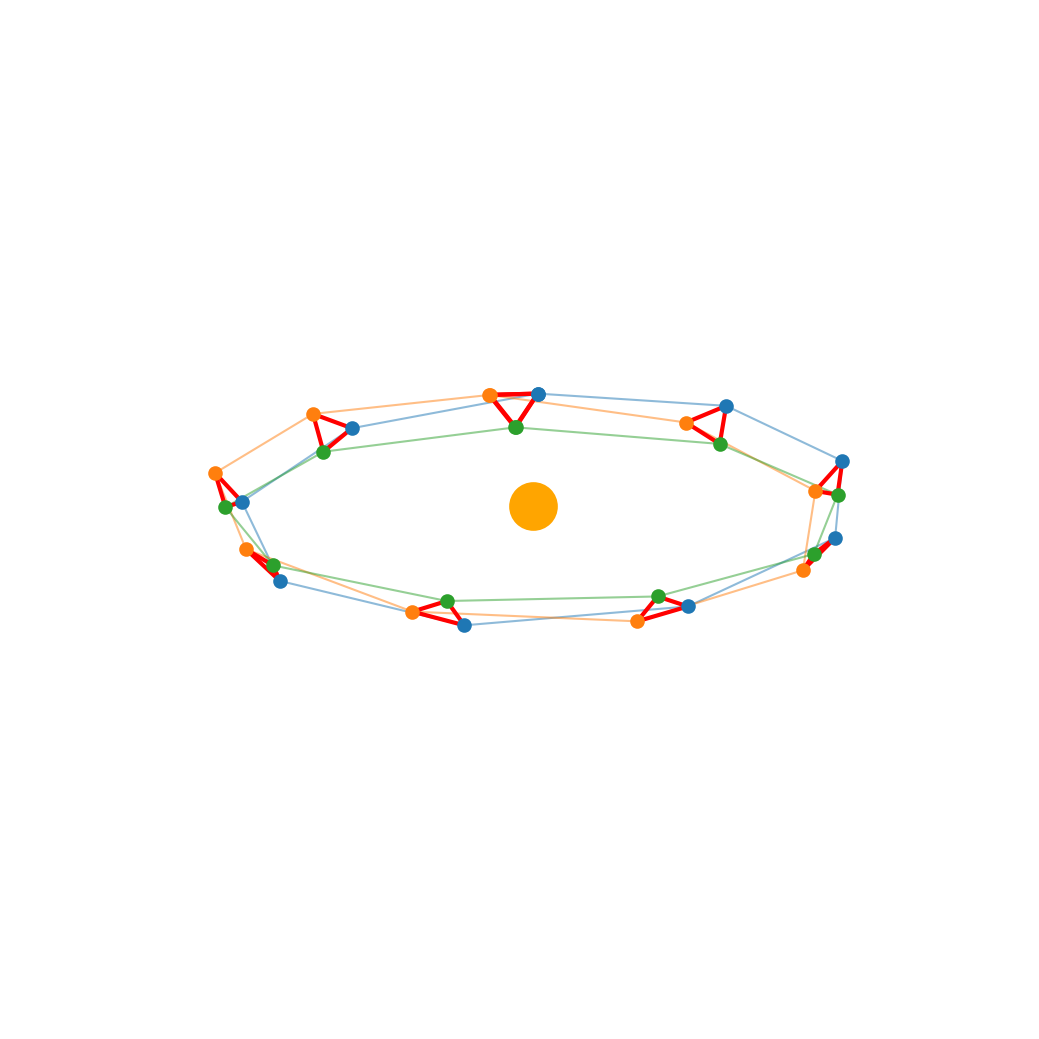

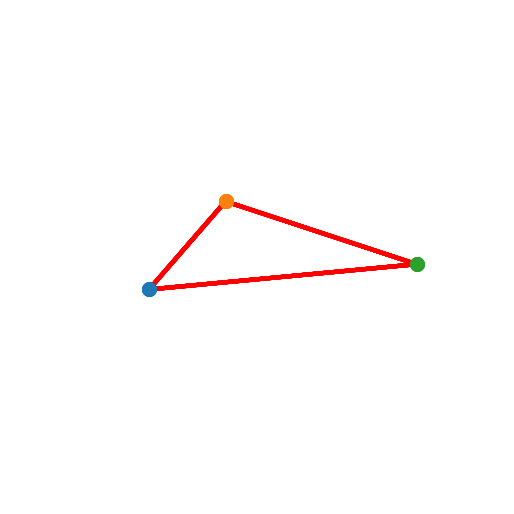

In [3]:
with h5py.File("data/processed_trajectories.h5", "r") as dset:
    t_orb_dataset = dset["t_interp"][()]
    x_orb_dataset = dset["spacecraft_positions"][()]
    v_orb_dataset = dset["spacecraft_velocities"][()]
    ltts_dataset = dset['owlt_12_23_31_13_32_21'][()]

    t_orb = t_orb_dataset
    x_orb = np.median(x_orb_dataset, axis=0)  # Use the median over all realizations
    v_orb = np.median(v_orb_dataset, axis=0)  # Use the median over all realizations
    ltts_median = np.median(ltts_dataset, axis=0)  # Use the median over all realizations
    orbital_info = {"t": t_orb, "x": x_orb, "v": v_orb, "ltt": ltts_median}

plot_orbit_3d(orbital_info, 1.0, output_file=os.path.join(PAPER_DIR, "lisa_orbit_.png"), figsize=(6*2, 2*3.5), include_sun=True)

orbits = StaticConstellation.from_armlengths(2.5e9, 2.5e9, 2.5e9)
orbital_info = {"t": t_orb, "x": orbits.compute_position(t_orb)}
plot_orbit_3d(orbital_info, 1.0, output_file=os.path.join(PAPER_DIR, "toy_orbit_.png"), figsize=(6, 3.5), include_sun=False)

In [4]:
# ── Case definitions ─────────────────────────────────────────────────────────
# Each entry:  human-readable label  →  path to the results directory
CASES = {
    "Arm-length (no boost)":          "segwo_results/static/arm1_rot0.0_trans0.0_boost0.0/",
    "Arm-length (boost)":             "segwo_results/static/arm1_rot0.0_trans0.0_boost1.0/",
    "Rotation (no boost)":     "segwo_results/static/arm0.0_rot50000.0_trans0.0_boost0.0/",
    "Rotation (boost)":        "segwo_results/static/arm0.0_rot50000.0_trans0.0_boost1.0/",
    "Translation (no boost)":  "segwo_results/static/arm0.0_rot0.0_trans50000.0_boost0.0/",
    "Translation (boost)":     "segwo_results/static/arm0.0_rot0.0_trans50000.0_boost1.0/",
    "Realistic (no boost)": "segwo_results/30.0days_evolving_boost0.0/",
    "Realistic (boost)":    "segwo_results/30.0days_evolving_boost1.0/",
    "Toy like realistic (boost)": "segwo_results/static/arm0.3_rot150.0_trans10000.0_boost1.0/",
}

# Reference case for the perturbation-distribution histograms
REFERENCE_CASE = "Arm-length (boost)"

In [5]:
# ── Data loading ──────────────────────────────────────────────────────────────
print("✓ Loading full results from segwo_results/")

✓ Loading full results from segwo_results/


In [6]:
def load_results(results_dir):
    """Load all relevant arrays from a results.h5 file."""
    hdf5_path = os.path.join(results_dir, "results.h5")
    if not os.path.exists(hdf5_path):
        raise FileNotFoundError(f"Missing: {hdf5_path}")
    with h5py.File(hdf5_path, "r") as hf:
        data = {
            "f":                     hf["metadata/frequencies"][()],
            "npix":                  int(hf["metadata"].attrs["npix"]),
            "nside":                 int(hf["metadata"].attrs["nside"]),
            "run_flag":              str(hf["metadata"].attrs["run_flag"]),
            "mismatch":              hf["errors/mismatch"][()],
            "strain2x_abs_error":    hf["errors/strain2x_abs_error"][()],
            "strain2x_angle_error":  hf["errors/strain2x_angle_error"][()],
            "strain2x_avg_rel_amp_error": hf["errors/strain2x_avg_rel_amp_error"][()],
        }
        # Optional datasets (not present in all files)
        for key, path in [
            ("angle",             "errors/angle"),
            ("ltt_residuals",     "perturbed/ltt_residuals"),
            ("position_residuals","perturbed/position_residuals"),
            ("mismatch_boost",    "nominal/mismatch_boost"),
            ("yaw_difference",   "errors/yaw_difference"),
            ("tilt_difference",  "errors/tilt_difference"),
            ("roll_difference",  "errors/roll_difference"),
        ]:
            if path in hf:
                data[key] = hf[path][()]
    return data

all_data = {}
for label, path in CASES.items():
    try:
        all_data[label] = load_results(path)
        d = all_data[label]
    except FileNotFoundError as e:
        print(f"✗  {label:28s}  {e}")

# Common frequency axis
if all_data:
    f = next(iter(all_data.values()))["f"]
    print(f"\nFrequency range: {f.min():.2e} – {f.max():.2e} Hz  ({f.size} points)")


Frequency range: 1.00e-04 – 1.00e+00 Hz  (149 points)


In [7]:

from cycler import cycler
# ── Publication-quality matplotlib settings ─────────────────────────────────
# Wong 2011 colorblind-friendly palette (8 colors)
# WONG_COLORS = [
#     '#000000',  # black
#     '#E69F00',  # orange
#     '#56B4E9',  # sky blue
#     '#009E73',  # bluish green
#     '#F0E442',  # yellow
#     '#0072B2',  # blue
#     '#D55E00',  # vermillion
#     '#CC79A7',  # reddish purple
# ]

COLORBLIND_PALETTE = [
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#009E73",  # bluish green
    "#F0E442",  # yellow
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#CC79A7"   # reddish purple
]

plt.rcParams.update({
    'text.usetex':       True,        # set True if a LaTeX install is available
    'font.family':       'times',
    'font.size':         9,
    'axes.labelsize':    9,
    'axes.titlesize':    9,
    'xtick.labelsize':   8,
    'ytick.labelsize':   8,
    'legend.fontsize':   8,
    'legend.frameon':    True,
    'legend.framealpha': 0.8,
    'figure.dpi':        150,
    'savefig.dpi':       300,
    'savefig.bbox':      'tight',
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'grid.linestyle':    ':',
    'lines.linewidth':   1.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.prop_cycle':   cycler('color', COLORBLIND_PALETTE),
})

## Orbital Perturbation Distributions

Histograms of the light-travel-time (LTT) residuals, spacecraft position residuals,
and orbit normal-vector angle offsets drawn from the Monte Carlo sample for the reference case.

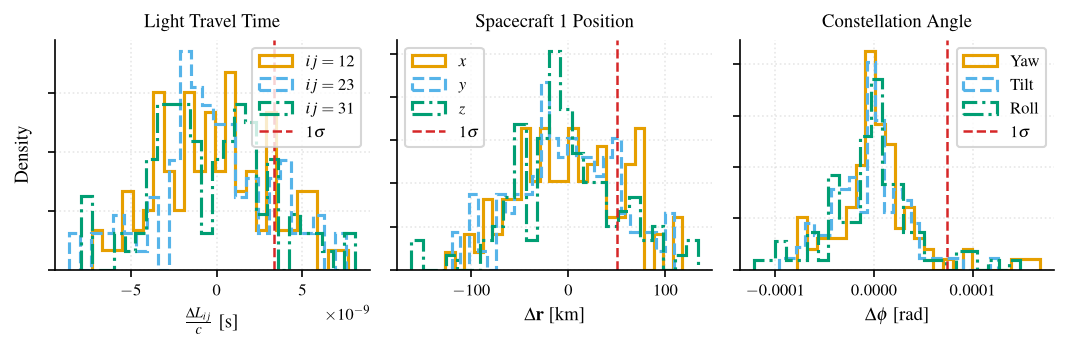

In [8]:
# "Arm (no boost)":          "segwo_results/static/arm1_rot0.0_trans0.0_boost0.0/",
# "Arm (boost)":             "segwo_results/static/arm1_rot0.0_trans0.0_boost1.0/",
# "Rotation (no boost)":     "segwo_results/static/arm0.0_rot50000.0_trans0.0_boost0.0/",
# "Rotation (boost)":        "segwo_results/static/arm0.0_rot50000.0_trans0.0_boost1.0/",
# "Translation (no boost)":  "segwo_results/static/arm0.0_rot0.0_trans50000.0_boost0.0/",
# "Translation (boost)":     "segwo_results/static/arm0.0_rot0.0_trans50000.0_boost1.0/",

ref = all_data["Arm-length (boost)"]
linestyle = ['-', '--', '-.']

fig, axes = plt.subplots(1, 3, figsize=(COL2, 2.4))

# ── LTT residuals ───────────────────────────────────────────────────────────
ref = all_data["Arm-length (boost)"]
ax = axes[0]
for i in range(3):
    ax.hist(
        ref["ltt_residuals"][:, i], bins=25,
        histtype='step', linestyle=linestyle[i], linewidth=1.5, density=True,
        # label=rf"$\Delta L_{{{LINKS[i]}}}$",
        label=rf"$ij = {{{LINKS[i]}}}$",
    )
ax.set_xlabel(r"$\frac{\Delta L_{ij}}{c}$ [s]")
ax.set_ylabel("Density")
ax.axvline(1.0/C, color='tab:red', ls='--', lw=1.2, label=r"$1\sigma$")
ax.set_yticklabels([])
ax.set_title("Light Travel Time")
ax.legend()
std_ltt = np.std(ref["ltt_residuals"], axis=0)

# ── Position residuals (SC 1) ────────────────────────────────────────────────
ref = all_data["Translation (boost)"]

ax = axes[1]
for i, lbl in enumerate(["$x$", "$y$", "$z$"]):
    ax.hist(
        ref["position_residuals"][:, 0, i] / 1e3, bins=25,
        histtype='step', linestyle=linestyle[i], linewidth=1.5, density=True,
        label=lbl,
    )
ax.set_xlabel(r"$\Delta \mathbf{r}$ [km]")
# ax.set_ylabel("Density")
ax.set_yticklabels([])
ax.axvline(50.0, color='tab:red', ls='--', lw=1.2, label=r"$1\sigma$")
ax.set_title("Spacecraft 1 Position")
ax.legend()
std_pos = np.std(ref["position_residuals"][:, 0, :], axis=0) / 1e3

# ── Orbit tilt angle ─────────────────────────────────────────────────────────
ref = all_data["Rotation (boost)"]
ax = axes[2]
dist_centroid = 2.5e9 * np.sqrt(1 / 3)
rot_fac = 2.127
expected_sigma = 50e3 * rot_fac / dist_centroid
# ax.hist(ref["angle"], bins=25, histtype='step', linewidth=1.5, density=True)
ax.hist(ref["yaw_difference"], bins=25, histtype='step', linewidth=1.5, density=True, label="Yaw")
ax.hist(ref["tilt_difference"], bins=25, histtype='step', linewidth=1.5, density=True, label="Tilt", linestyle='--')
mask_off = ref["roll_difference"] < -5
roll_diff = ref["roll_difference"].copy()
roll_diff[mask_off] = roll_diff[mask_off] + np.pi * 2
ax.hist(roll_diff, bins=25, histtype='step', linewidth=1.5, density=True, label="Roll", linestyle='-.')
ax.axvline(expected_sigma, color='tab:red', ls='--', lw=1.2, label=r"$1\sigma$")
ax.set_xlabel(r"$\Delta\phi$ [rad]")
# ax.set_ylabel("Density")
ax.set_yticklabels([])
ax.set_title("Constellation Angle")
ax.legend()
std_angle = np.std(ref["angle"], axis=0)
std_yaw = np.std(ref["yaw_difference"], axis=0)
std_tilt = np.std(ref["tilt_difference"], axis=0)
std_roll = np.std(roll_diff, axis=0)

plt.tight_layout()
plt.savefig(os.path.join(PAPER_DIR, "static_orbit_perturbation_distributions.png"), dpi=300)
plt.show()


In [9]:
ref.keys()

dict_keys(['f', 'npix', 'nside', 'run_flag', 'mismatch', 'strain2x_abs_error', 'strain2x_angle_error', 'strain2x_avg_rel_amp_error', 'angle', 'ltt_residuals', 'position_residuals', 'mismatch_boost', 'yaw_difference', 'tilt_difference', 'roll_difference'])

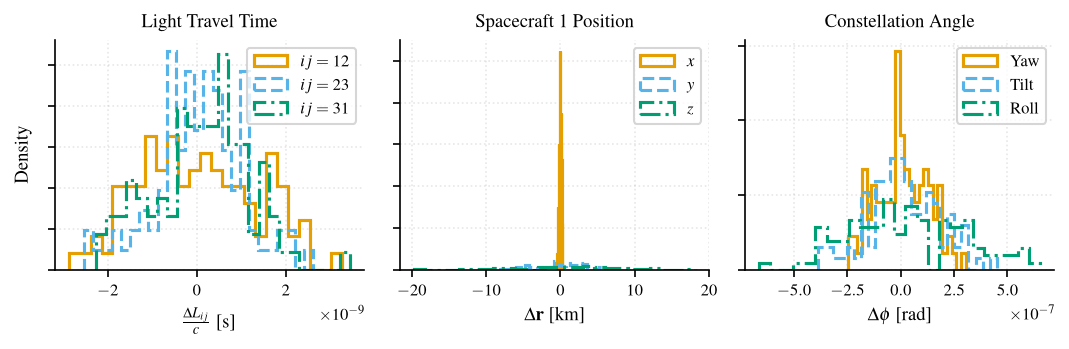

In [10]:
ref = all_data["Realistic (boost)"]
linestyle = ['-', '--', '-.']

fig, axes = plt.subplots(1, 3, figsize=(COL2, 2.4))

# ── LTT residuals ───────────────────────────────────────────────────────────
ax = axes[0]
for i in range(3):
    ax.hist(
        ref["ltt_residuals"][:, i], bins=25,
        histtype='step', linestyle=linestyle[i], linewidth=1.5, density=True,
        # label=rf"$\Delta L_{{{LINKS[i]}}}$",
        label=rf"$ij = {{{LINKS[i]}}}$",
    )
ax.set_xlabel(r"$\frac{\Delta L_{ij}}{c}$ [s]")
ax.set_ylabel("Density")
ax.set_yticklabels([])
ax.set_title("Light Travel Time")
ax.legend()
std_ltt_real = np.std(ref["ltt_residuals"], axis=0)

# ── Position residuals (SC 1) ────────────────────────────────────────────────
ax = axes[1]
for i, lbl in enumerate(["$x$", "$y$", "$z$"]):
    ax.hist(
        ref["position_residuals"][:, 0, i] / 1e3, bins=25,
        histtype='step', linestyle=linestyle[i], linewidth=1.5, density=True,
        label=lbl,
    )
ax.set_xlabel(r"$\Delta \mathbf{r}$ [km]")
# ax.set_ylabel("Density")
ax.set_yticklabels([])
ax.set_title("Spacecraft 1 Position")
ax.legend()
std_pos_real = np.std(ref["position_residuals"][:, 0, :], axis=0) / 1e3

# ── Orbit tilt angle ─────────────────────────────────────────────────────────
ax = axes[2]
dist_centroid = 2.5e9 * np.sqrt(1 / 3)
expected_sigma = 50e3 * 2.13 / dist_centroid
# ax.hist(ref["angle"], bins=25, histtype='step', linewidth=1.5, density=True)
ax.hist(ref["yaw_difference"], bins=25, histtype='step', linewidth=1.5, density=True, label="Yaw")
ax.hist(ref["tilt_difference"], bins=25, histtype='step', linewidth=1.5, density=True, label="Tilt", linestyle='--')
mask_off = ref["roll_difference"] < -5
roll_diff = ref["roll_difference"].copy()
roll_diff[mask_off] = roll_diff[mask_off] + np.pi * 2
ax.hist(roll_diff, bins=25, histtype='step', linewidth=1.5, density=True, label="Roll", linestyle='-.')
ax.set_xlabel(r"$\Delta\phi$ [rad]")
# ax.set_ylabel("Density")
ax.set_yticklabels([])
ax.set_title("Constellation Angle")
ax.legend()
std_angle_real = np.std(ref["angle"], axis=0)
std_tilt_real = np.std(ref["tilt_difference"], axis=0)
std_roll_real = np.std(roll_diff, axis=0)
std_yaw_real = np.std(ref["yaw_difference"], axis=0)

# fig.suptitle(f"Reference case: {REFERENCE_CASE}", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(PAPER_DIR, "evolving_orbit_perturbation_distributions.png"), dpi=300)
plt.show()


In [11]:
# print std values for toy and realistic cases
print("Toy orbit (Arm-length boost):")
print(f"  LTT std:   {std_ltt} s")
print(f"  Position std: {std_pos} km")
print(f"  Angle std: {std_angle} rad")

print("\nRealistic orbit (Arm-length boost):")
print(f"  LTT std:   {std_ltt_real} s", std_ltt_real*C, "m")
print(f"  Position std: {std_pos_real} km")
print(f"  Angle std: {std_angle_real} rad")
# print ratios  
print("=" * 40)
print("\nRatios (Toy/Realistic):")
print(f"  LTT std ratio:   {std_ltt / std_ltt_real}")
print(f"  Position std ratio: {std_pos / std_pos_real}")
# print(f"  Angle std ratio: {std_angle / std_angle_real}")
print(f"\n  Angle std ratio: {std_angle / std_angle_real}")  # --- IGNORE ---
print(f"  Yaw std ratio: {std_yaw / std_angle_real}")
print(f"  Tilt std ratio: {std_tilt / std_angle_real}")
print(f"  Roll std ratio: {std_roll / std_angle_real}")


Toy orbit (Arm-length boost):
  LTT std:   [3.25095865e-09 3.38981023e-09 3.31819230e-09 3.31819230e-09
 3.38981023e-09 3.25095865e-09] s
  Position std: [53.78539683 50.80966425 53.95698576] km
  Angle std: 3.6814769657240024e-05 rad

Realistic orbit (Arm-length boost):
  LTT std:   [1.30721134e-09 9.86650957e-10 1.08438550e-09 1.06233971e-09
 1.00253337e-09 1.30857184e-09] s [0.3918921  0.29579052 0.3250906  0.31848143 0.30055194 0.39229997] m
  Position std: [0.14328924 3.04128577 6.97707664] km
  Angle std: 1.4285902927332646e-07 rad

Ratios (Toy/Realistic):
  LTT std ratio:   [2.48694189 3.43567318 3.05997479 3.12347573 3.3812443  2.48435627]
  Position std ratio: [375.36241971  16.70663928   7.73346611]

  Angle std ratio: 257.69998469472864
  Yaw std ratio: 298.71912022835573
  Tilt std ratio: 260.4310955649994
  Roll std ratio: 316.2449579437154


## Amplitude and Phase errors

In [12]:
all_data.keys()
data = all_data["Realistic (no boost)"]
print("Realistic (no boost) strain2x_abs_error shape:", data["strain2x_abs_error"].shape)
data = all_data["Realistic (boost)"]
print("Realistic (boost) strain2x_abs_error shape:", data["strain2x_abs_error"].shape)

Realistic (no boost) strain2x_abs_error shape: (149, 432, 3, 2)
Realistic (boost) strain2x_abs_error shape: (149, 432, 3, 2)


Realistic (no boost):
  Amplitude error at 1e-04 Hz: 3.88e-04
  Phase error at 1e-04 Hz: 1.16e-04
  Amplitude error at 1e-03 Hz: 2.10e-04
  Phase error at 1e-03 Hz: 8.60e-05
  Amplitude error at 1e-02 Hz: 1.34e-04
  Phase error at 1e-02 Hz: 5.97e-05
  Amplitude error at 1e+00 Hz: 1.15e-03
  Phase error at 1e+00 Hz: 1.35e-03
Realistic (boost):
  Amplitude error at 1e-04 Hz: 1.44e-05
  Phase error at 1e-04 Hz: 7.70e-06
  Amplitude error at 1e-03 Hz: 4.95e-06
  Phase error at 1e-03 Hz: 3.32e-06
  Amplitude error at 1e-02 Hz: 2.82e-06
  Phase error at 1e-02 Hz: 3.23e-06
  Amplitude error at 1e+00 Hz: 9.33e-06
  Phase error at 1e+00 Hz: 2.48e-04


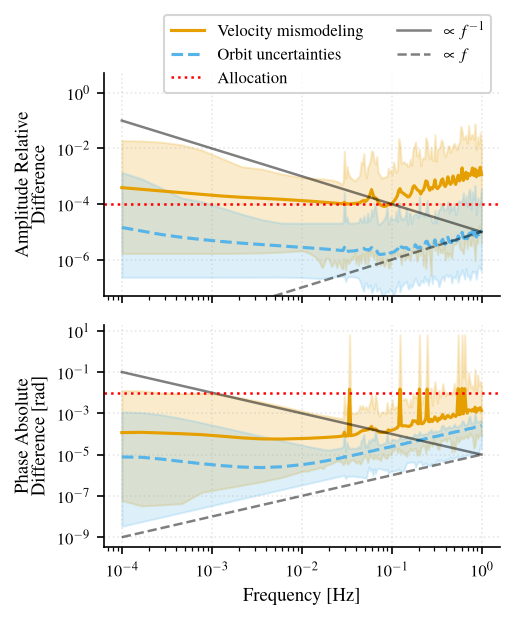

In [13]:
pols=('$h_+$', r'$h_\times$')

fig, axs = plt.subplots(2, 1, figsize=(COL1, 1.2*COL1), sharex=True)

ch = 0 # which TDI channel
pol = 0
labels = ['Velocity mismodeling', 'Orbit uncertainties']
linestyle = ['-', '--']

for i, name in enumerate(['Realistic (no boost)', 'Realistic (boost)']):
    data = all_data[name]
    
    # Full results: (F, N_real, 3, 2) - compute means and min/max
    amp_err = data["strain2x_abs_error"]  # (F, N_real, 3, 2)
    freq_mean_abs = np.mean(amp_err, axis=1)[:, ch, pol]
    freq_min = np.min(amp_err, axis=1)[:, ch, pol]
    freq_max = np.max(amp_err, axis=1)[:, ch, pol]
    
    axs[0].fill_between(f, freq_min, freq_max, alpha=0.2, color=f'C{i}')
    axs[0].loglog(f, freq_mean_abs, label=labels[i], color=f'C{i}', linestyle=linestyle[i])
    
    # Phase errors
    angle_err = data["strain2x_angle_error"]  # (F, N_real, 3, 2)
    freq_mean_angle = np.mean(angle_err, axis=1)[:, ch, pol]
    freq_min = np.min(angle_err, axis=1)[:, ch, pol]
    freq_max = np.max(angle_err, axis=1)[:, ch, pol]
    
    axs[1].fill_between(f, freq_min, freq_max, alpha=0.2, color=f'C{i}')
    axs[1].loglog(f, freq_mean_angle, label=labels[i], color=f'C{i}', linestyle=linestyle[i])
    
    # Summary statistics
    print(f"{name}:")
    test_f = np.asarray([1e-4, 1e-3, 1e-2, 1])
    for tf in test_f:
        print(f"  Amplitude error at {tf:.0e} Hz: {np.interp(tf, f, freq_mean_abs):.2e}")
        print(f"  Phase error at {tf:.0e} Hz: {np.interp(tf, f, freq_mean_angle):.2e}")

axs[0].axhline(1e-4, color='r', ls=':', lw=1.2, label="Allocation")
axs[0].set_ylabel("Amplitude Relative \nDifference")
axs[0].loglog(f, 1e-5/f, color='k', ls=linestyle[0], lw=1.2, label=r"$\propto f^{-1}$", alpha=0.5)
axs[0].loglog(f, 1e-5*f, color='k', ls=linestyle[1], lw=1.2, label=r"$\propto f$", alpha=0.5)
axs[0].legend(ncol=2, title_fontsize=10, bbox_to_anchor=(1., 1.3))
axs[1].loglog(f, 1e-5/f, color='k', ls=linestyle[0], lw=1.2, label=r"$\propto f^{-1}$", alpha=0.5)
axs[1].loglog(f, 1e-5*f, color='k', ls=linestyle[1], lw=1.2, label=r"$\propto f$", alpha=0.5)

axs[0].set_ylim(0.5e-7, 5)
axs[1].set_xlabel("Frequency [Hz]")
axs[1].set_ylabel("Phase Absolute \nDifference [rad]")
axs[1].axhline(1e-2, color='r', ls=':', lw=1.2, label="Allocation")
plt.tight_layout()
plt.savefig("paper_plots/amplitude_phase_errors.png", dpi=300)

Velocity
mismodeling:
  Amplitude error at 0.10 mHz: 8.73e-05
  Phase error at 0.10 mHz: 1.16e-04
  Amplitude error at 1.00 mHz: 8.67e-05
  Phase error at 1.00 mHz: 8.60e-05
  Amplitude error at 10.00 mHz: 8.22e-05
  Phase error at 10.00 mHz: 5.97e-05
  Amplitude error at 1000.00 mHz: 7.02e-04
  Phase error at 1000.00 mHz: 1.35e-03
Orbit
uncertainties:
  Amplitude error at 0.10 mHz: 1.59e-06
  Phase error at 0.10 mHz: 7.70e-06
  Amplitude error at 1.00 mHz: 1.57e-06
  Phase error at 1.00 mHz: 3.32e-06
  Amplitude error at 10.00 mHz: 1.48e-06
  Phase error at 10.00 mHz: 3.23e-06
  Amplitude error at 1000.00 mHz: 5.50e-06
  Phase error at 1000.00 mHz: 2.48e-04


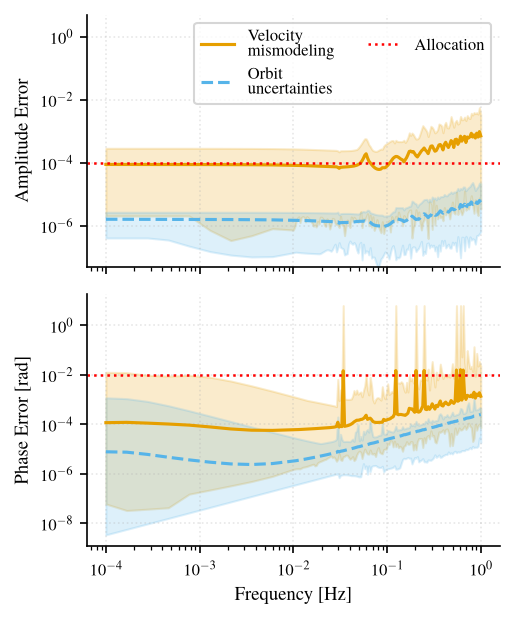

In [14]:
pols=('$h_+$', r'$h_\times$')

fig, axs = plt.subplots(2, 1, figsize=(COL1, 1.2*COL1), sharex=True)

ch = 0
pol = 0
labels = ['Velocity\nmismodeling', 'Orbit\nuncertainties']
linestyle = ['-', '--']

for i, name in enumerate(['Realistic (no boost)', 'Realistic (boost)']):
    data = all_data[name]
    
    # Full results: (F, N_real, 3, 2) - compute means and min/max
    amp_err = data["strain2x_avg_rel_amp_error"]  # (F, N_real, 3, 2)
    freq_mean_abs = np.mean(amp_err, axis=1)[:, ch, pol]
    freq_min = np.min(amp_err, axis=1)[:, ch, pol]
    freq_max = np.max(amp_err, axis=1)[:, ch, pol]
    
    axs[0].fill_between(f, freq_min, freq_max, alpha=0.2, color=f'C{i}')
    axs[0].loglog(f, freq_mean_abs, label=labels[i], color=f'C{i}', linestyle=linestyle[i])
    
    # Phase errors
    angle_err = data["strain2x_angle_error"]  # (F, N_real, 3, 2)
    freq_mean_angle = np.mean(angle_err, axis=1)[:, ch, pol]
    freq_min = np.min(angle_err, axis=1)[:, ch, pol]
    freq_max = np.max(angle_err, axis=1)[:, ch, pol]
    
    axs[1].fill_between(f, freq_min, freq_max, alpha=0.2, color=f'C{i}')
    axs[1].loglog(f, freq_mean_angle, label=labels[i], color=f'C{i}', linestyle=linestyle[i])
    
    # Summary statistics
    print(f"{labels[i]}:")
    f_test = np.asarray([1e-4, 1e-3, 1e-2, 1])
    for tf in f_test:
            print(f"  Amplitude error at {tf*1000:.2f} mHz: {np.interp(tf, f, freq_mean_abs):.2e}")
            print(f"  Phase error at {tf*1000:.2f} mHz: {np.interp(tf, f, freq_mean_angle):.2e}")

axs[0].axhline(1e-4, color='r', ls=':', lw=1.2, label="Allocation")
axs[0].set_ylabel("Amplitude Error")
# axs[0].loglog(f, 1e-5/f, color='k', ls=linestyle[0], lw=1.2, label=r"$\propto f^{-1}$", alpha=0.5)
# axs[0].loglog(f, 1e-5*f, color='k', ls=linestyle[1], lw=1.2, label=r"$\propto f$", alpha=0.5)
axs[0].legend(ncol=2, title_fontsize=10)#, bbox_to_anchor=(1., 1.2))
axs[0].set_ylim(0.5e-7, 5)
axs[1].set_xlabel("Frequency [Hz]")
axs[1].set_ylabel("Phase Error [rad]")
axs[1].axhline(1e-2, color='r', ls=':', lw=1.2, label="Allocation")
plt.tight_layout()
plt.savefig("paper_plots/requirement_amplitude_phase_errors.png", dpi=300)

# 3. Mismatch vs GW Frequency

The mismatch $\mathcal{M} = 1 - \langle h_\mathrm{pert}, h_\mathrm{nom} \rangle / \sqrt{\langle h_\mathrm{pert}, h_\mathrm{pert}\rangle\,\langle h_\mathrm{nom}, h_\mathrm{nom}\rangle}$
measures the overlap degradation caused by orbit perturbations.


Arm-length (boost) mismatch shape: (100, 149, 432, 2)
Arm-length (boost) - $h_+$: Mismatch at 0.10 mHz = 6.55e-13
Arm-length (boost) - $h_+$: Mismatch at 1.00 mHz = 6.39e-16
Arm-length (boost) - $h_+$: Mismatch at 10.00 mHz = 8.74e-17
Arm-length (boost) - $h_+$: Mismatch at 100.00 mHz = 8.03e-17
Arm-length (boost) - $h_\times$: Mismatch at 0.10 mHz = 6.22e-13
Arm-length (boost) - $h_\times$: Mismatch at 1.00 mHz = 6.17e-16
Arm-length (boost) - $h_\times$: Mismatch at 10.00 mHz = 8.68e-17
Arm-length (boost) - $h_\times$: Mismatch at 100.00 mHz = 7.73e-17
Translation (boost) mismatch shape: (100, 149, 432, 2)
Translation (boost) - $h_+$: Mismatch at 0.10 mHz = 6.15e-15
Translation (boost) - $h_+$: Mismatch at 1.00 mHz = 6.55e-13
Translation (boost) - $h_+$: Mismatch at 10.00 mHz = 6.15e-11
Translation (boost) - $h_+$: Mismatch at 100.00 mHz = 6.15e-09
Translation (boost) - $h_\times$: Mismatch at 0.10 mHz = 6.15e-15
Translation (boost) - $h_\times$: Mismatch at 1.00 mHz = 6.55e-13
Transl

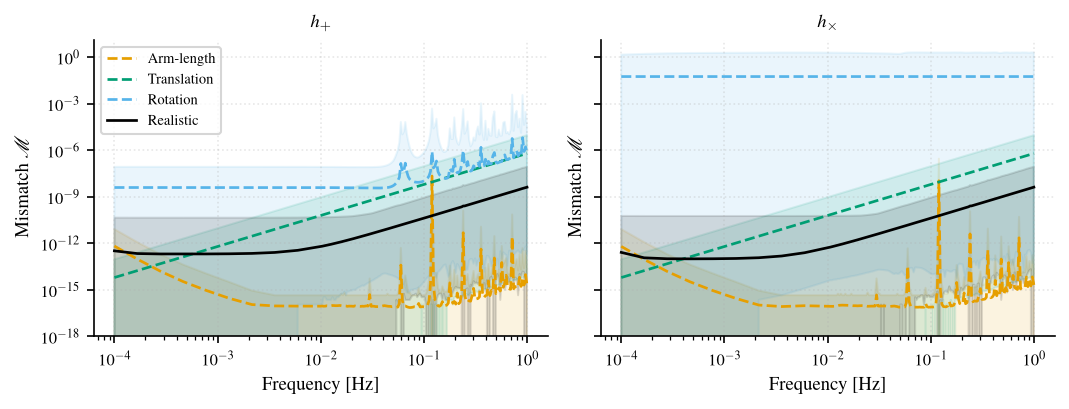

In [15]:
# Colorblind-friendly palette (Wong 2011)
STYLES = {
    "Arm-length (boost)":             dict(color=COLORBLIND_PALETTE[0], ls="--", lw=1.3),
    "Translation (boost)":     dict(color=COLORBLIND_PALETTE[2], ls="--", lw=1.3),
    "Rotation (boost)":        dict(color=COLORBLIND_PALETTE[1], ls="--", lw=1.3),
    # "Toy like realistic (boost)": dict(color=COLORBLIND_PALETTE[4], ls="--", lw=1.3), # add this if you want check how the toy like realistic case compares to the realistic one
    "Realistic (boost)":    dict(color="k", ls="-", lw=1.3),
}

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.8), sharex=True, sharey=True)

for label, style in STYLES.items():
    if label not in all_data:
        continue
    
    mm = np.nan_to_num(all_data[label]["mismatch"])  # (N_real, F, sky, 2)
    print(f"{label} mismatch shape: {mm.shape}")
    freq_mean = mm.mean(axis=(0, 2))   # (F, 2)
    freq_min  = mm.min(axis=(0, 2))    # (F, 2)
    freq_max  = mm.max(axis=(0, 2))    # (F, 2)
    
    for j, ax in enumerate(axes):
        ax.fill_between(f, freq_min[:, j], freq_max[:, j],
                        color=style["color"], alpha=0.12)
        ax.plot(f, freq_mean[:, j],
                ls=style["ls"], lw=style["lw"], color=style["color"],
                label=label[:-8] if j == 0 else None)
        # print(np.sum((freq_min[:, j] < freq_mean[:, j]) * (freq_mean[:, j] < freq_max[:, j]))/freq_mean[:, j].size)
        for test_f in [1e-4, 1e-3, 1e-2, 1e-1]:
            print(f"{label} - {POLS[j]}: Mismatch at {test_f*1000:.2f} mHz = {np.interp(test_f, f, freq_mean[:, j]):.2e}")

for j, ax in enumerate(axes):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel(r"Mismatch $\mathcal{M}$")
    ax.set_title(POLS[j])
    ax.set_ylim(bottom=1e-18)

axes[0].legend(fontsize=7, ncol=1, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(PAPER_DIR, "mismatch_vs_frequency.png"), dpi=300)
plt.show()

Arm-length (boost) mismatch shape: (100, 149, 432, 2)
1.0
Arm-length (boost) - $h_+$: Mismatch at 1 mHz = 6.39e-16
Arm-length (boost) - $h_+$: Mismatch at 100 mHz = 8.03e-17
1.0
Arm-length (boost) - $h_\times$: Mismatch at 1 mHz = 6.17e-16
Arm-length (boost) - $h_\times$: Mismatch at 100 mHz = 7.73e-17
Rotation (boost) mismatch shape: (100, 149, 432, 2)
1.0
Rotation (boost) - $h_+$: Mismatch at 1 mHz = 3.91e-09
Rotation (boost) - $h_+$: Mismatch at 100 mHz = 1.04e-08
1.0
Rotation (boost) - $h_\times$: Mismatch at 1 mHz = 5.56e-02
Rotation (boost) - $h_\times$: Mismatch at 100 mHz = 5.56e-02
Translation (boost) mismatch shape: (100, 149, 432, 2)
1.0
Translation (boost) - $h_+$: Mismatch at 1 mHz = 6.55e-13
Translation (boost) - $h_+$: Mismatch at 100 mHz = 6.15e-09
1.0
Translation (boost) - $h_\times$: Mismatch at 1 mHz = 6.55e-13
Translation (boost) - $h_\times$: Mismatch at 100 mHz = 6.15e-09
Toy like realistic (boost) mismatch shape: (100, 149, 432, 2)
1.0
Toy-model calibrated to rea

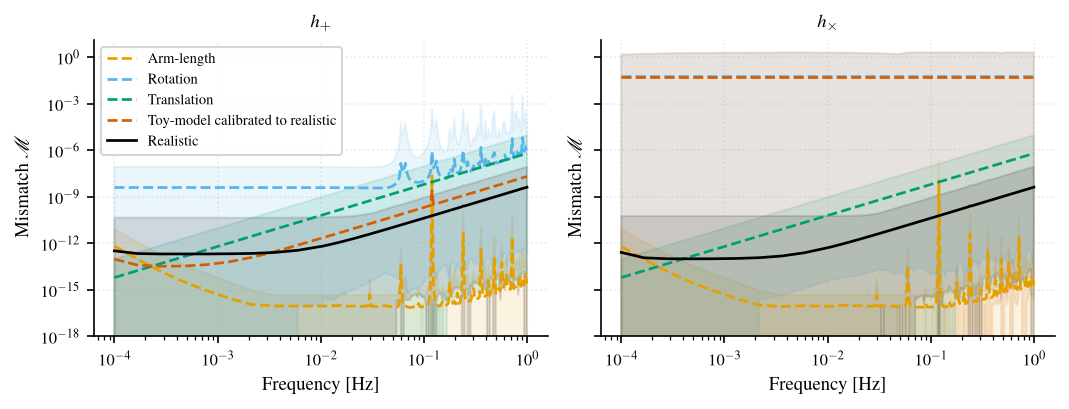

In [16]:
# Colorblind-friendly palette (Wong 2011)
STYLES = {
    "Arm-length (boost)":             dict(color=COLORBLIND_PALETTE[0], ls="--", lw=1.3),
    "Rotation (boost)":        dict(color=COLORBLIND_PALETTE[1], ls="--", lw=1.3),
    "Translation (boost)":     dict(color=COLORBLIND_PALETTE[2], ls="--", lw=1.3),
    "Toy like realistic (boost)": dict(color=COLORBLIND_PALETTE[5], ls="--", lw=1.3), # add this if you want check how the toy like realistic case compares to the realistic one
    "Realistic (boost)":    dict(color="k", ls="-", lw=1.3),
}

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.8), sharex=True, sharey=True)

for label, style in STYLES.items():
    if label not in all_data:
        continue
    
    mm = np.nan_to_num(all_data[label]["mismatch"])  # (N_real, F, sky, 2)
    print(f"{label} mismatch shape: {mm.shape}")
    freq_mean = mm.mean(axis=(0, 2))   # (F, 2)
    freq_min  = mm.min(axis=(0, 2))    # (F, 2)
    freq_max  = mm.max(axis=(0, 2))    # (F, 2)
    
    for j, ax in enumerate(axes):
        if label == "Toy like realistic (boost)":
            label = "Toy-model calibrated to realistic (boost)"
        else:
            ax.fill_between(f, freq_min[:, j], freq_max[:, j],
                        color=style["color"], alpha=0.12)
        ax.plot(f, freq_mean[:, j],
                ls=style["ls"], lw=style["lw"], color=style["color"],
                label=label[:-8] if j == 0 else None)
        print(np.sum((freq_min[:, j] < freq_mean[:, j]) * (freq_mean[:, j] < freq_max[:, j]))/freq_mean[:, j].size)
        print(f"{label} - {POLS[j]}: Mismatch at 1 mHz = {np.interp(1e-3, f, freq_mean[:, j]):.2e}")
        print(f"{label} - {POLS[j]}: Mismatch at 100 mHz = {np.interp(1e-1, f, freq_mean[:, j]):.2e}")

for j, ax in enumerate(axes):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel(r"Mismatch $\mathcal{M}$")
    ax.set_title(POLS[j])
    ax.set_ylim(bottom=1e-18)

axes[0].legend(fontsize=7, ncol=1, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(PAPER_DIR, "mismatch_vs_frequency_toy_like_realistic.png"), dpi=300)
plt.show()

Arm-length (boost) mismatch shape: (100, 149, 432, 2)
1.0
Arm-length (boost) - $h_+$: Mismatch at 1 mHz = 6.39e-16
Arm-length (boost) - $h_+$: Mismatch at 100 mHz = 8.03e-17
1.0
Arm-length (boost) - $h_\times$: Mismatch at 1 mHz = 6.17e-16
Arm-length (boost) - $h_\times$: Mismatch at 100 mHz = 7.73e-17
Rotation (boost) mismatch shape: (100, 149, 432, 2)
1.0
Rotation (boost) - $h_+$: Mismatch at 1 mHz = 3.91e-09
Rotation (boost) - $h_+$: Mismatch at 100 mHz = 1.04e-08
1.0
Rotation (boost) - $h_\times$: Mismatch at 1 mHz = 5.56e-02
Rotation (boost) - $h_\times$: Mismatch at 100 mHz = 5.56e-02
Translation (boost) mismatch shape: (100, 149, 432, 2)
1.0
Translation (boost) - $h_+$: Mismatch at 1 mHz = 6.55e-13
Translation (boost) - $h_+$: Mismatch at 100 mHz = 6.15e-09
1.0
Translation (boost) - $h_\times$: Mismatch at 1 mHz = 6.55e-13
Translation (boost) - $h_\times$: Mismatch at 100 mHz = 6.15e-09
Toy like realistic (boost) mismatch shape: (100, 149, 432, 2)
1.0
Toy-model calibrated to rea

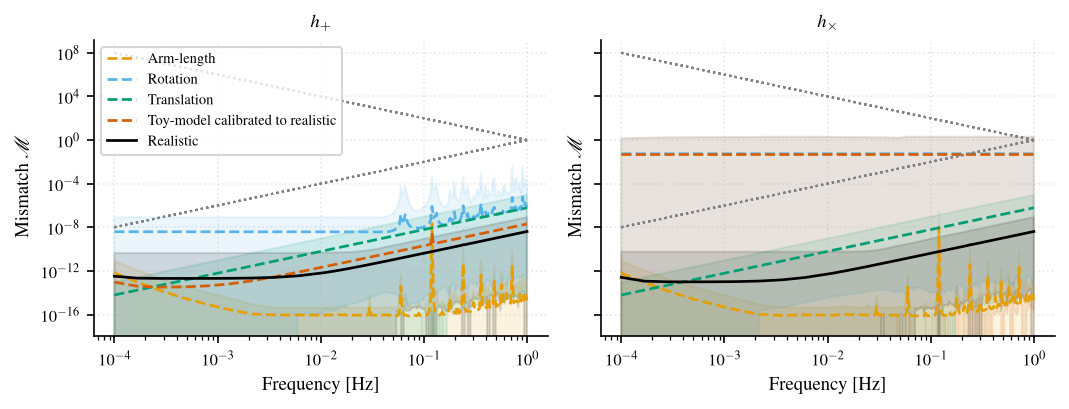

In [17]:
# Colorblind-friendly palette (Wong 2011)
STYLES = {
    "Arm-length (boost)":             dict(color=COLORBLIND_PALETTE[0], ls="--", lw=1.3),
    "Rotation (boost)":        dict(color=COLORBLIND_PALETTE[1], ls="--", lw=1.3),
    "Translation (boost)":     dict(color=COLORBLIND_PALETTE[2], ls="--", lw=1.3),
    "Toy like realistic (boost)": dict(color=COLORBLIND_PALETTE[5], ls="--", lw=1.3), # add this if you want check how the toy like realistic case compares to the realistic one
    "Realistic (boost)":    dict(color="k", ls="-", lw=1.3),
}

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.8), sharex=True, sharey=True)

for label, style in STYLES.items():
    if label not in all_data:
        continue
    
    mm = np.nan_to_num(all_data[label]["mismatch"])  # (N_real, F, sky, 2)
    print(f"{label} mismatch shape: {mm.shape}")
    freq_mean = mm.mean(axis=(0, 2))   # (F, 2)
    freq_min  = mm.min(axis=(0, 2))    # (F, 2)
    freq_max  = mm.max(axis=(0, 2))    # (F, 2)
    
    for j, ax in enumerate(axes):
        if label == "Toy like realistic (boost)":
            label = "Toy-model calibrated to realistic (boost)"
        else:
            ax.fill_between(f, freq_min[:, j], freq_max[:, j],
                        color=style["color"], alpha=0.12)
        ax.plot(f, freq_mean[:, j],
                ls=style["ls"], lw=style["lw"], color=style["color"],
                label=label[:-8] if j == 0 else None)
        ax.plot(f, f**2, ls=":", lw=1, color="gray")
        ax.plot(f, f**-2, ls=":", lw=1, color="gray")
        print(np.sum((freq_min[:, j] < freq_mean[:, j]) * (freq_mean[:, j] < freq_max[:, j]))/freq_mean[:, j].size)
        print(f"{label} - {POLS[j]}: Mismatch at 1 mHz = {np.interp(1e-3, f, freq_mean[:, j]):.2e}")
        print(f"{label} - {POLS[j]}: Mismatch at 100 mHz = {np.interp(1e-1, f, freq_mean[:, j]):.2e}")

for j, ax in enumerate(axes):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel(r"Mismatch $\mathcal{M}$")
    ax.set_title(POLS[j])
    ax.set_ylim(bottom=1e-18)
    

axes[0].legend(fontsize=7, ncol=1, loc="upper left")
plt.tight_layout()
# plt.savefig(os.path.join(PAPER_DIR, "mismatch_vs_frequency_toy_like_realistic.png"), dpi=300)
plt.show()

## Mismatch Sky Maps

In [18]:
all_data.keys()

dict_keys(['Arm-length (no boost)', 'Arm-length (boost)', 'Rotation (no boost)', 'Rotation (boost)', 'Translation (no boost)', 'Translation (boost)', 'Realistic (no boost)', 'Realistic (boost)', 'Toy like realistic (boost)'])


Processing case: Realistic (boost)


/opt/miniconda3/envs/resp/lib/python3.12/site-packages/healpy/visufunc.py:225: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


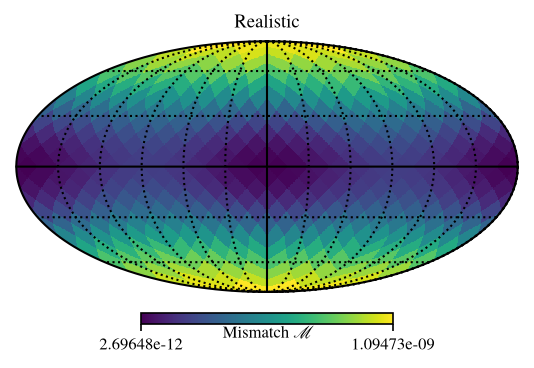

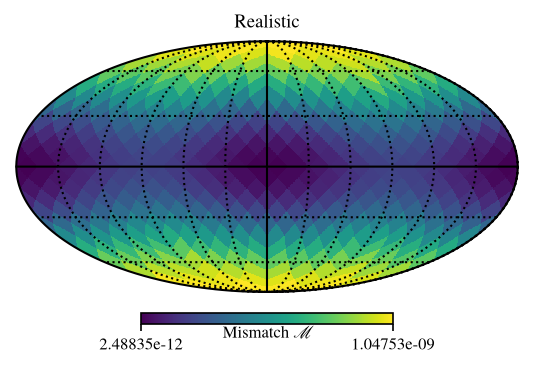


Processing case: Arm-length (boost)


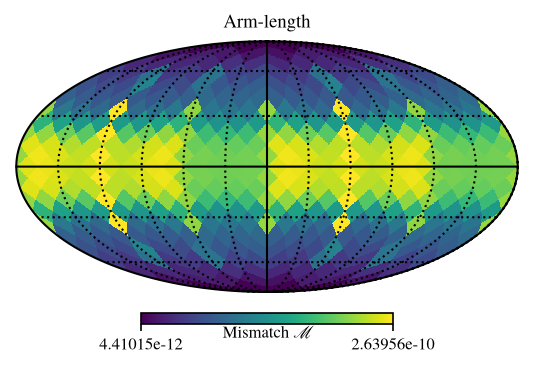

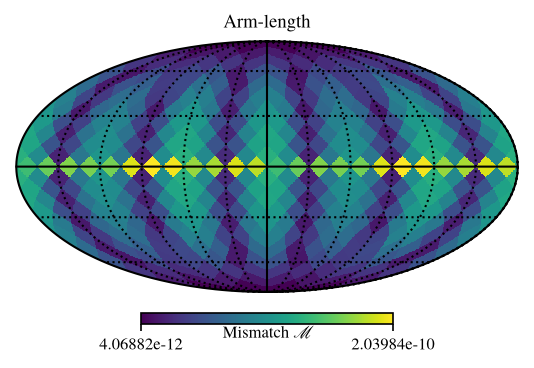


Processing case: Rotation (boost)


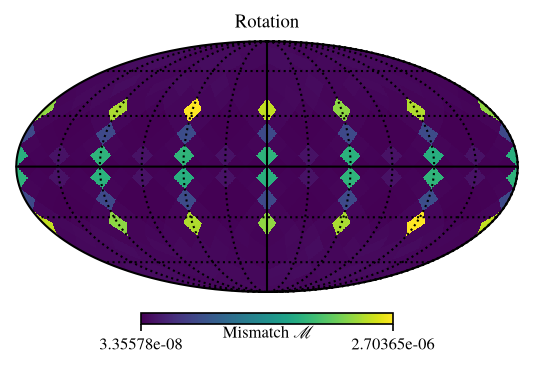

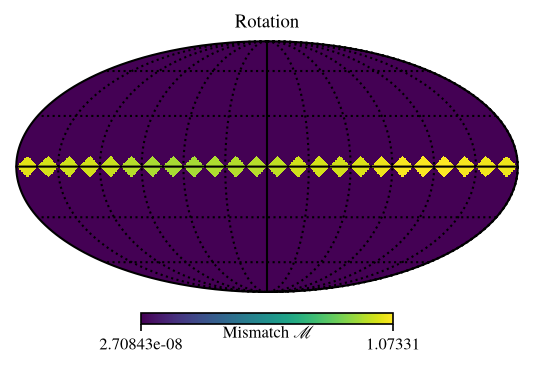


Processing case: Translation (boost)


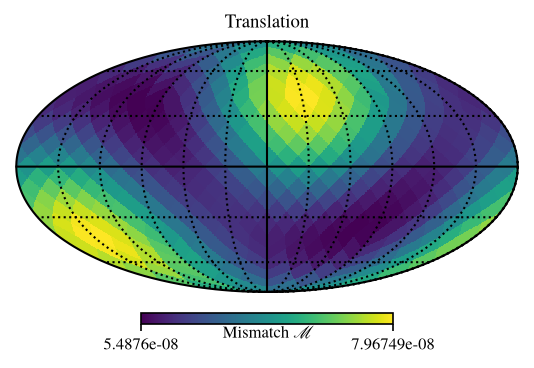

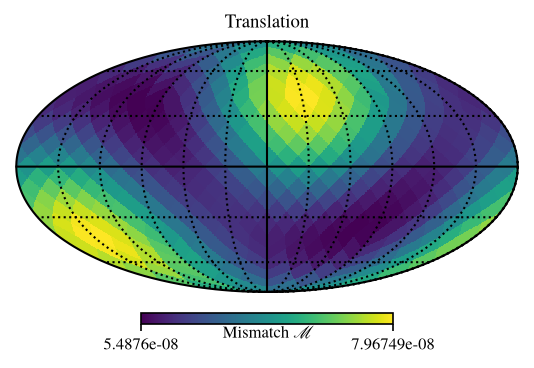

In [19]:
for MAP_CASE in ["Realistic (boost)", "Arm-length (boost)", "Rotation (boost)", "Translation (boost)"]:
    print("="*60)
    print(f"\nProcessing case: {MAP_CASE}")
    d    = all_data[MAP_CASE]
    mm   = np.nan_to_num(d["mismatch"])   # (N, F, P, 2)
    npix = d["npix"]

    # ── Mollweide sky maps ───────────────────────────────────────────────────────
    for j, pol in enumerate(POLS):
        sky_map = mm.mean(axis=(0, 1))[:, j]   # (P,) – max over realisations & freq
        fig = plt.figure(figsize=(COL1, 3))
        hp.mollview(
            sky_map,
            title=f"{MAP_CASE[:-8]}",
            rot=[0, 0], 
            fig=fig.number,
            unit=r"Mismatch $\mathcal{M}$",
            fontsize={'cbar_label': 8},
        )
        hp.graticule()
        fname = f"mismatch_sky_{pol.replace('$','').replace('_','').replace('+','p').replace('\\times','x')}.png"
        plt.show()

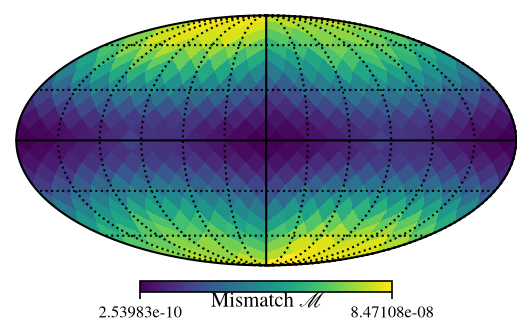

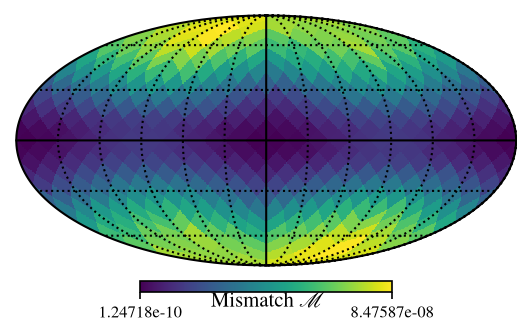

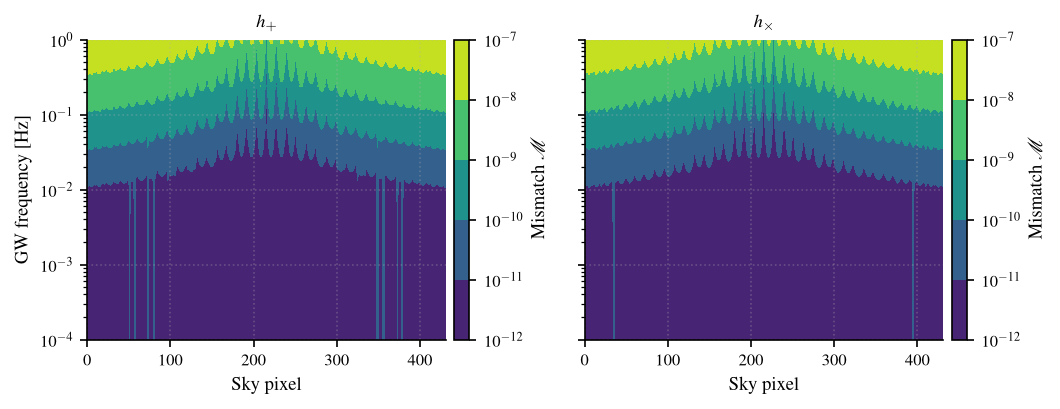

In [20]:
MAP_CASE = "Realistic (boost)"
d    = all_data[MAP_CASE]
mm   = np.nan_to_num(d["mismatch"])   # (N, F, P, 2)
npix = d["npix"]

# ── Mollweide sky maps ───────────────────────────────────────────────────────
for j, pol in enumerate(POLS):
    sky_map = mm.max(axis=(0, 1))[:, j]   # (P,) – max over realisations & freq
    fig = plt.figure(figsize=(COL1, 2.2))
    hp.mollview(
        sky_map,
        title=f"",
        rot=[0, 0], 
        fig=fig.number,
        unit=r"Mismatch $\mathcal{M}$",
        fontsize={'xlabel': 10, 'ylabel': 10, 'title': 10, 'cbar_label': 10},
    )
    hp.graticule()
    fname = f"mismatch_sky_{pol.replace('$','').replace('_','').replace('+','p').replace('\\times','x')}.pdf"
    plt.show()

# ── Frequency–sky contour ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.8), sharey=True)

for j, (ax, pol) in enumerate(zip(axes, POLS)):
    z = mm.max(axis=0)[:, :, j]         # (F, P) – max over realisations
    vmin = max(1e-12, float(z.min()))
    vmax = min(1.0,   float(z.max()))
    z = z.clip(vmin, vmax)
    dmin = int(np.floor(np.log10(vmin)))
    dmax = int(np.ceil(np.log10(vmax)))
    levels = np.logspace(dmin, dmax, max(2, dmax - dmin + 1))
    cf = ax.contourf(
        np.arange(npix), f, z,
        levels=levels, norm=LogNorm(vmin=vmin, vmax=vmax), cmap="viridis",
    )
    ax.set_yscale("log")
    ax.set_xlabel("Sky pixel")
    ax.set_title(pol)
    cbar = fig.colorbar(cf, ax=ax, pad=0.02)
    cbar.set_label(r"Mismatch $\mathcal{M}$")

axes[0].set_ylabel("GW frequency [Hz]")
plt.tight_layout()
plt.show()

# Mismatch of Galactic Binary

<KeysViewHDF5 ['f0_vec', 'mismatch_nonrel_vs_rel_test', 'mismatch_nonrel_vs_rel_with_nominal', 'mismatch_nonrel_vs_rel_with_perturbed', 'mismatch_perturbed_vs_nominal_with_nonrel', 'mismatch_perturbed_vs_nominal_with_rel']>
Mismatch at 0.10 mHz for Perturbed vs Nominal Orbits: 7.19e-14
Mismatch at 1.00 mHz for Perturbed vs Nominal Orbits: 5.96e-14
Mismatch at 10.00 mHz for Perturbed vs Nominal Orbits: 4.25e-13
Mismatch at 100.00 mHz for Perturbed vs Nominal Orbits: 3.17e-11
Mismatch at 0.10 mHz for Non-Boosted vs Boosted Response: 8.54e-09
Mismatch at 1.00 mHz for Non-Boosted vs Boosted Response: 8.70e-09
Mismatch at 10.00 mHz for Non-Boosted vs Boosted Response: 6.85e-09
Mismatch at 100.00 mHz for Non-Boosted vs Boosted Response: 9.43e-09


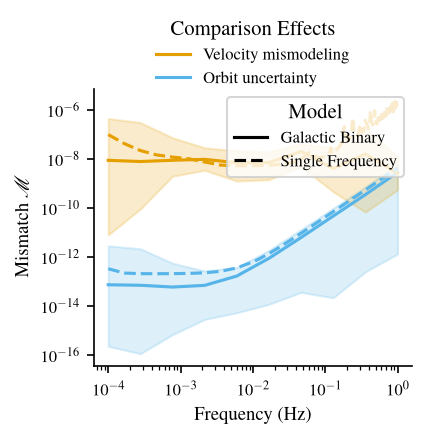

In [21]:
from matplotlib.lines import Line2D

output_file = f"data/gb_mismatch_results_30.0days.h5"

mismatch = {}
with h5py.File(output_file, "r") as f:
    print(f.keys())
    f0_vec = f["f0_vec"][()]
    for key in f.keys():
        if key.startswith("mismatch_"):
            mismatch[key] = f[key][()]

labels = {
    "mismatch_perturbed_vs_nominal_with_rel": "Perturbed vs Nominal Orbits",
    "mismatch_nonrel_vs_rel_with_nominal": "Non-Boosted vs Boosted Response",
}

plt.figure(figsize=(COL1/1.2, COL1/1.1))

key = "mismatch_perturbed_vs_nominal_with_rel"
y_mean = mismatch[key].mean(axis=1)
y_min = mismatch[key].min(axis=1)
y_max = mismatch[key].max(axis=1)
plt.fill_between(f0_vec, y_min, y_max, alpha=0.2, color='C1')
plt.plot(f0_vec, y_mean, '-', label=labels[key], color='C1')
for test_f in [1e-4, 1e-3, 1e-2, 1e-1]:
    print(f"Mismatch at {test_f*1000:.2f} mHz for {labels['mismatch_perturbed_vs_nominal_with_rel']}: {np.interp(test_f, f0_vec, y_mean):.2e}")

key = "mismatch_nonrel_vs_rel_with_nominal"
y_mean = mismatch[key].mean(axis=1)
y_min = mismatch[key].min(axis=1)
y_max = mismatch[key].max(axis=1)
plt.fill_between(f0_vec, y_min, y_max, alpha=0.2, color='C0')
plt.plot(f0_vec, y_mean, '-', label=labels[key], color='C0')

for test_f in [1e-4, 1e-3, 1e-2, 1e-1]:
    print(f"Mismatch at {test_f*1000:.2f} mHz for {labels['mismatch_nonrel_vs_rel_with_nominal']}: {np.interp(test_f, f0_vec, y_mean):.2e}")

f = all_data["Realistic (no boost)"]["f"]
mm_no_boost = np.nan_to_num(all_data["Realistic (no boost)"]["mismatch"])
mean_no_boost = mm_no_boost.mean(axis=(0, 2))[:, 0]

mm_boost = np.nan_to_num(all_data["Realistic (boost)"]["mismatch"])
mean_boost = mm_boost.mean(axis=(0, 2))[:, 0]

plt.loglog(f, mean_no_boost, ls='--', color='C0')
plt.loglog(f, mean_boost, ls='--', color='C1')
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"Mismatch $\mathcal{M}$")
ax = plt.gca()

style_handles = [
    Line2D([0], [0], color='k', ls='-', label='Galactic Binary'),
    Line2D([0], [0], color='k', ls='--', label='Single Frequency'),
]

color_handles = [
    Line2D([0], [0], color='C0', lw=1.5, label='Velocity mismodeling'),
    Line2D([0], [0], color='C1', lw=1.5, label='Orbit uncertainty'),
]

legend_style = ax.legend(handles=style_handles, title="Model", loc="upper right", title_fontsize=10)
ax.add_artist(legend_style)
ax.legend(handles=color_handles, title="Comparison Effects", loc="upper center", bbox_to_anchor=(0.5, 1.3), ncol=1, title_fontsize=10, frameon=True, framealpha=0.0)
plt.grid()
plt.tight_layout()
plt.savefig(os.path.join(PAPER_DIR, f"gb_mismatch_plot.png"), dpi=300, bbox_inches='tight')
plt.show()